
############################################################
 PROCESSING TARGET: NS1
############################################################
Fitting 5 folds for each of 16 candidates, totalling 80 fits

----------------------------------------
Random Forest — NS1
----------------------------------------
Accuracy: 0.8875
              precision    recall  f1-score   support

           0     0.9535    0.8092    0.8754       152
           1     0.8407    0.9623    0.8974       159

    accuracy                         0.8875       311
   macro avg     0.8971    0.8857    0.8864       311
weighted avg     0.8958    0.8875    0.8866       311



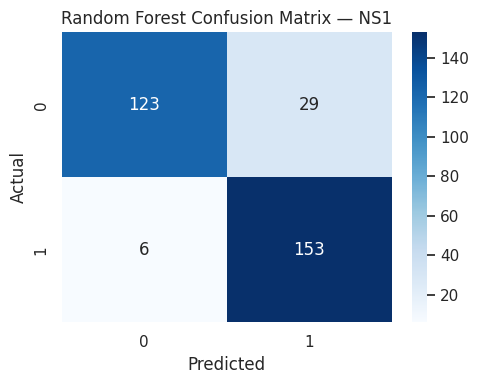

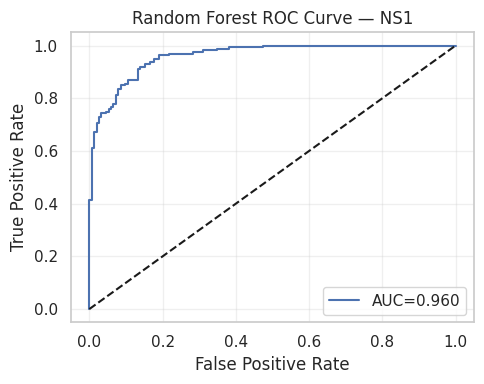

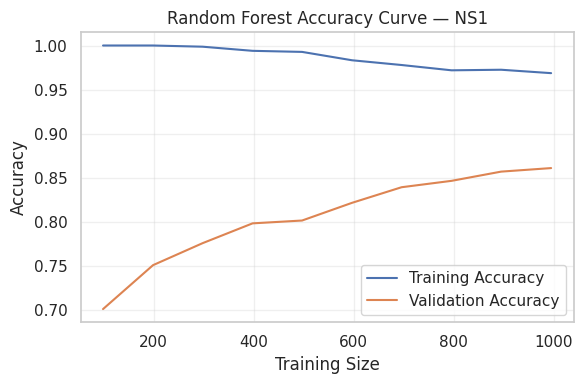

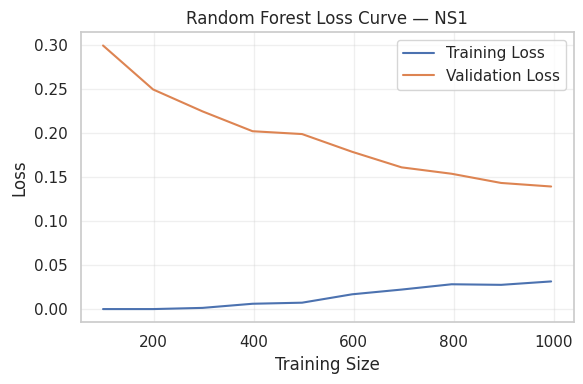


----------------------------------------
AdaBoost (Optimized) — NS1
----------------------------------------
Accuracy: 0.8328
              precision    recall  f1-score   support

           0     0.8333    0.8224    0.8278       152
           1     0.8323    0.8428    0.8375       159

    accuracy                         0.8328       311
   macro avg     0.8328    0.8326    0.8327       311
weighted avg     0.8328    0.8328    0.8328       311



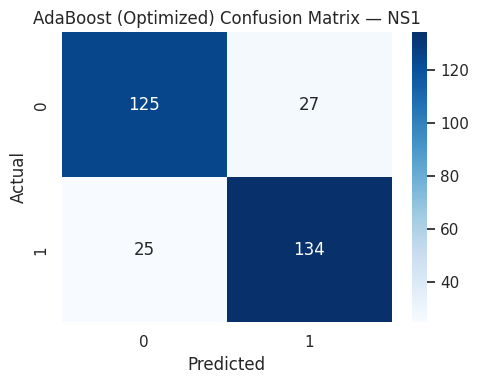

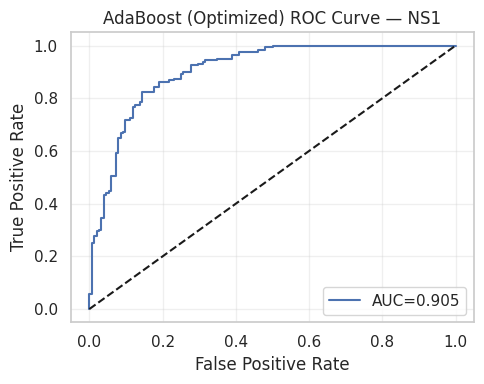

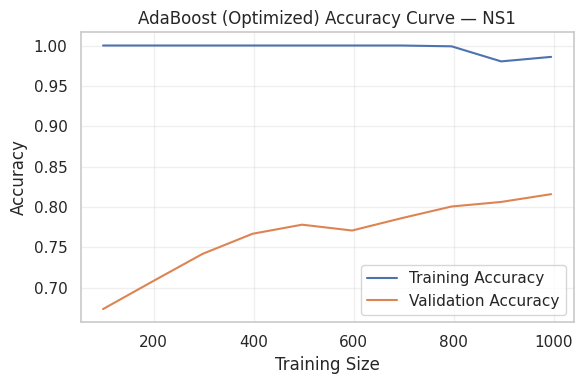

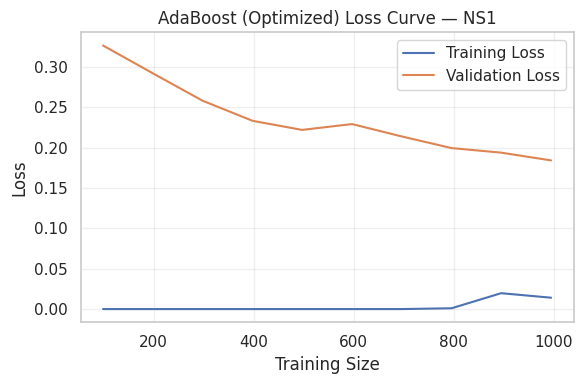


----------------------------------------
Decision Tree — NS1
----------------------------------------
Accuracy: 0.8392
              precision    recall  f1-score   support

           0     0.8750    0.7829    0.8264       152
           1     0.8114    0.8931    0.8503       159

    accuracy                         0.8392       311
   macro avg     0.8432    0.8380    0.8383       311
weighted avg     0.8425    0.8392    0.8386       311



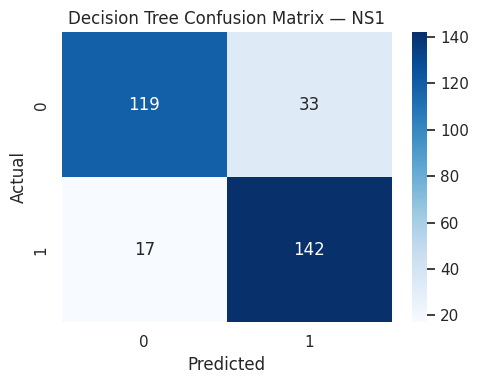

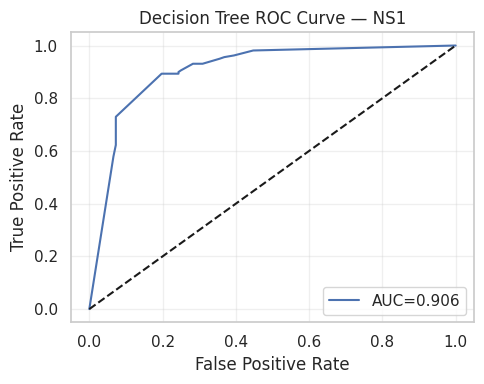

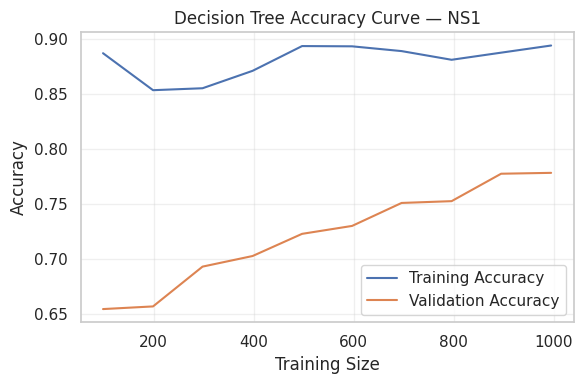

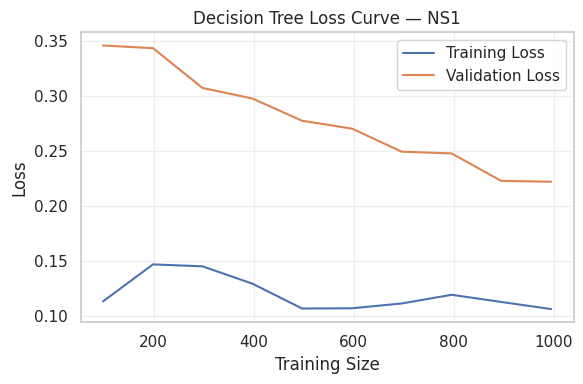


----------------------------------------
KNN — NS1
----------------------------------------
Accuracy: 0.9100
              precision    recall  f1-score   support

           0     0.9429    0.8684    0.9041       152
           1     0.8830    0.9497    0.9152       159

    accuracy                         0.9100       311
   macro avg     0.9129    0.9091    0.9096       311
weighted avg     0.9123    0.9100    0.9098       311



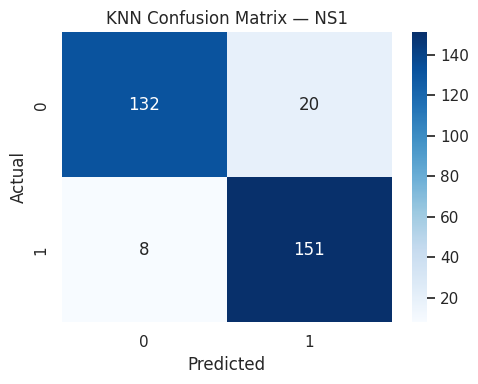

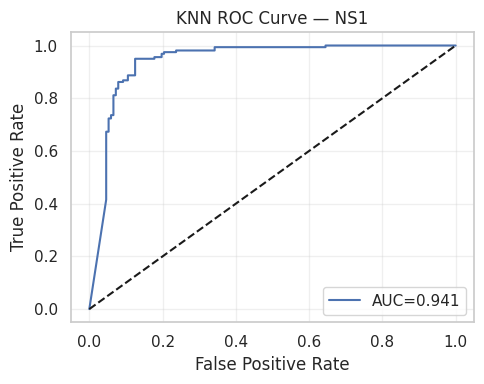

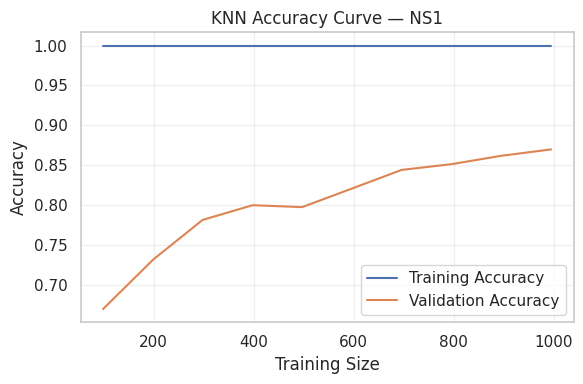

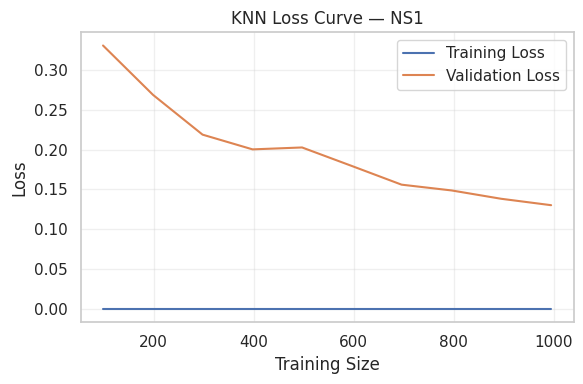

Completed target: NS1

✅ ALL MODELS, CONFUSION MATRICES, ROC & TRAIN/VAL CURVES COMPLETED.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, auc, log_loss
)

# ----------------------------
# 1) Load dataset
# ----------------------------
df = pd.read_excel("/content/Final_dataset.xlsx")

# ----------------------------
# 2) Label encoding
# ----------------------------
encoders = {}
for col in df.columns:
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])
        encoders[col] = le

# ----------------------------
# 3) Targets loop
# ----------------------------
targets = ["NS1"]

for tgt in targets:
    print("\n" + "#" * 60)
    print(f" PROCESSING TARGET: {tgt}")
    print("#" * 60)

    df_sub = df[df[tgt].notna()].copy()
    X = df_sub.drop(columns=[tgt])
    y = df_sub[tgt].values
    classes = np.unique(y)
    n_classes = len(classes)

    # ----------------------------
    # Train/Test split
    # ----------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # ----------------------------
    # Models
    # ----------------------------
    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    base_tree = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42
    )

    ada_grid = GridSearchCV(
        AdaBoostClassifier(
            estimator=base_tree,
            random_state=42
        ),
        param_grid={
            'n_estimators': [50, 100, 200, 300],
            'learning_rate': [0.01, 0.1, 1, 1.5]
        },
        cv=5,
        scoring='f1_weighted',
        n_jobs=-1,
        verbose=1
    )

    dt = DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42
    )

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    knn = KNeighborsClassifier(
        n_neighbors=7,
        weights='distance'
    )

    # ----------------------------
    # Fit models
    # ----------------------------
    rf.fit(X_train, y_train)
    ada_grid.fit(X_train, y_train)
    best_ada = ada_grid.best_estimator_
    dt.fit(X_train, y_train)
    knn.fit(X_train_sc, y_train)

    models = {
        "Random Forest": (rf, X_train, X_test),
        "AdaBoost (Optimized)": (best_ada, X_train, X_test),
        "Decision Tree": (dt, X_train, X_test),
        "KNN": (knn, X_train_sc, X_test_sc)
    }

    # ----------------------------
    # Evaluation loop
    # ----------------------------
    for name, (model, X_tr, X_ev) in models.items():
        print("\n" + "-" * 40)
        print(f"{name} — {tgt}")
        print("-" * 40)

        y_pred = model.predict(X_ev)
        acc = accuracy_score(y_test, y_pred)
        print(f"Accuracy: {acc:.4f}")
        print(classification_report(y_test, y_pred, digits=4))

        # Confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(5,4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f"{name} Confusion Matrix — {tgt}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.tight_layout()
        plt.show()

        # ROC curve
        plt.figure(figsize=(5,4))
        if n_classes == 2:
            y_prob = model.predict_proba(X_ev)[:,1]
            fpr, tpr, _ = roc_curve(y_test, y_prob)
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
        else:
            y_test_bin = label_binarize(y_test, classes=classes)
            y_prob = model.predict_proba(X_ev)
            fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
            roc_auc_val = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"Macro AUC={roc_auc_val:.3f}")
        plt.plot([0,1],[0,1],"k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"{name} ROC Curve — {tgt}")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        # ----------------------------
        # TRAINING VS VALIDATION CURVES
        # ----------------------------
        train_sizes, train_scores, val_scores = learning_curve(
            model,
            X_tr,
            y_train,
            cv=5,
            scoring='accuracy',
            train_sizes=np.linspace(0.1,1.0,10)
        )
        train_mean = train_scores.mean(axis=1)
        val_mean = val_scores.mean(axis=1)

        # Accuracy curve
        plt.figure(figsize=(6,4))
        plt.plot(train_sizes, train_mean, label="Training Accuracy")
        plt.plot(train_sizes, val_mean, label="Validation Accuracy")
        plt.title(f"{name} Accuracy Curve — {tgt}")
        plt.xlabel("Training Size")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Loss curve (1 - accuracy)
        train_loss = 1 - train_mean
        val_loss = 1 - val_mean
        plt.figure(figsize=(6,4))
        plt.plot(train_sizes, train_loss, label="Training Loss")
        plt.plot(train_sizes, val_loss, label="Validation Loss")
        plt.title(f"{name} Loss Curve — {tgt}")
        plt.xlabel("Training Size")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    print(f"Completed target: {tgt}")

print("\n✅ ALL MODELS, CONFUSION MATRICES, ROC & TRAIN/VAL CURVES COMPLETED.")


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Reload the dataset to define 'df'
df = pd.read_excel('/content/Final_dataset.xlsx')

# Apply the same preprocessing as before
for col in df.columns:
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])

print('✅ Data loaded and preprocessed. You can now run the evaluation cells.')

✅ Data loaded and preprocessed. You can now run the evaluation cells.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')